# AudioSet-Tools v2 — demo notebook

This notebook walks through the `audioset_tools` package on the small excerpts shipped in `tests/data/` (30 AudioSet clips, 7 AudioSet Strong segments with 43 events, 40 VGGSound rows, and **synthetic** SALT-like files). It needs no network, no other repository and writes only to a temporary folder. Run it from a clone of the repository after `pip install -e ".[plot]"`.

The package supports three YouTube-backed metadata families, detected automatically and normalized into `AudioRecord` objects:

- **AudioSet Standard**: weak-label CSV (`YTID`, `start_seconds`, `end_seconds`, `positive_labels`);
- **AudioSet Strong**: temporally strong TSV (`segment_id`, event boundaries, MID label);
- **VGGSound**: CSV (`youtube_id`, `start_seconds`, text label, split).

Everything downstream (filtering in the `id`/`original`/`salt`/`auto` query spaces, grouping, statistics, rebalancing, merging, export, event tracks, download jobs) works through the same API. To work on the complete official files, point `PATHS` to them (see `docs/usage.md`); the SALT assets are fetched with `audioset-tools fetch-salt` (`docs/salt.md`).

## 1. Setup

The next cell finds the repository root, imports the package and defines the paths of the excerpts and a temporary output folder.

In [1]:
from pathlib import Path
import json
import tempfile

import matplotlib.pyplot as plt

from audioset_tools import (
    AUDIOSET,
    AUDIOSET_STRONG,
    VGGSOUND,
    AudioDataset,
    AudioRecord,
    DownloadJob,
    SaltResolver,
    YouTubeDatasetDownloader,
    blacklist_labels,
    compute_stats,
    detect_format,
    filter_labels,
    find_samples_by_samples,
    find_samples_by_youtube_ids,
    generate_event_tracks,
    iter_events,
    load_dataset,
    load_label_map,
    merge_datasets,
    parse_metadata,
    plot_events_pianoroll,
    read_download_report,
    rebalance,
    select_range,
)

# The repository root is the nearest parent that holds pyproject.toml and tests/data.
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "pyproject.toml").exists() and (p / "tests" / "data").exists())
DATA = ROOT / "tests" / "data"

PATHS = {
    "audioset_eval": DATA / "audioset" / "eval_segments_excerpt.csv",
    "audioset_labels": DATA / "audioset" / "class_labels_indices_excerpt.csv",
    "strong_eval": DATA / "audioset_strong" / "audioset_eval_strong_excerpt.tsv",
    "strong_labels": DATA / "audioset_strong" / "mid_to_display_name_excerpt.tsv",
    "vggsound": DATA / "vggsound" / "vggsound_excerpt.csv",
    "salt_mapping": DATA / "salt" / "salt_event_mapping.tsv",
    "salt_roots": DATA / "salt" / "salt_event_roots.json",
}
OUTPUT_DIR = Path(tempfile.mkdtemp(prefix="audioset_tools_demo_"))


def show_table(rows):
    """Print a list of dictionaries as an aligned text table."""
    columns = list(rows[0])
    widths = [max(len(str(c)), *(len(str(r[c])) for r in rows)) for c in columns]
    print(" | ".join(str(c).ljust(w) for c, w in zip(columns, widths)))
    print("-+-".join("-" * w for w in widths))
    for r in rows:
        print(" | ".join(str(r[c]).ljust(w) for c, w in zip(columns, widths)))


print("tests/data found:", DATA.is_dir())
print("excerpts:", ", ".join(sorted(p.name for p in PATHS.values())))

tests/data found: True
excerpts: audioset_eval_strong_excerpt.tsv, class_labels_indices_excerpt.csv, eval_segments_excerpt.csv, mid_to_display_name_excerpt.tsv, salt_event_mapping.tsv, salt_event_roots.json, vggsound_excerpt.csv


## 2. Automatic format detection

`detect_format(...)` inspects the schema and content of each file, so no separate public API is needed for Standard, Strong or already processed files.

In [2]:
for name in ["audioset_eval", "strong_eval", "vggsound"]:
    print(f"{name:14s} -> {detect_format(PATHS[name])}")

audioset_eval  -> AudioSet
strong_eval    -> AudioSetStrong
vggsound       -> VggSound


## 3. Original label maps

AudioSet files use MIDs such as `/m/09x0r`. `load_label_map` reads the MID to display-name tables (two layouts); VGGSound already stores text labels.

In [3]:
audioset_label_map = load_label_map(PATHS["audioset_labels"])
strong_label_map = load_label_map(PATHS["strong_labels"])
print("AudioSet label map size:", len(audioset_label_map))
print("AudioSet Strong label map size:", len(strong_label_map))
for mid, label in list(audioset_label_map.items())[:4]:
    print(f"  {mid:12s} -> {label}")

AudioSet label map size: 51
AudioSet Strong label map size: 20
  /m/09x0r     -> Speech
  /m/02zsn     -> Female speech, woman speaking
  /t/dd00001   -> Baby laughter
  /m/07sq110   -> Belly laugh


## 4. SALT label space

`SaltResolver` is optional. Without it everything works on the original labels; with it each record also carries standardized SALT events. The real SALT files are **not distributed** with this package (the upstream repository declares no licence): fetch them with `audioset-tools fetch-salt` and call `SaltResolver.from_mapping_file()`. This notebook uses the **synthetic** files of `tests/data/salt`, which have the same layout but invented event names.

In [4]:
salt = SaltResolver.from_mapping_file(PATHS["salt_mapping"], PATHS["salt_roots"])
print("descendants of 'vehicle':", salt.descendants("vehicle"))
print("descendants of 'music' (a root nested inside itself, as in the real file):", salt.descendants("music"))
print()
print("AudioSet / Domestic animals, pets ->", salt.resolve(AUDIOSET, ["Domestic animals, pets"]))
print("AudioSetStrong / Train wheels squealing ->", salt.resolve(AUDIOSET_STRONG, ["Train wheels squealing"]))
print("VggSound / ambulance siren ->", salt.resolve(VGGSOUND, ["ambulance siren"]))

descendants of 'vehicle': ('road_vehicle', 'rail_vehicle', 'aircraft', 'siren_ringing', 'car', 'engine', 'train', 'ambulance_siren', 'idling')
descendants of 'music' (a root nested inside itself, as in the real file): ('singing',)

AudioSet / Domestic animals, pets -> ('animal',)
AudioSetStrong / Train wheels squealing -> ('train',)
VggSound / ambulance siren -> ('ambulance_siren',)


### 4.1 Integration through `py_salt`

`SaltResolver.from_py_salt()` uses a `py_salt.EventExplorer` (optional extra `salt`: Python < 3.12, numpy < 2). Without it, `from_mapping_file()` remains the recommended path.

In [5]:
try:
    salt_from_py_salt = SaltResolver.from_py_salt()
    print("SaltResolver.from_py_salt() OK")
    print("VggSound / people marching ->", salt_from_py_salt.resolve(VGGSOUND, ["people marching"]))
except Exception as exc:
    print("py_salt integration is not available in this environment:")
    print(type(exc).__name__, "-", str(exc).split(". ")[0])

py_salt integration is not available in this environment:
ImportError - py_salt is not importable


## 5. Normalized parsing of the three datasets

`AudioDataset.from_file(...)` creates immutable `AudioRecord` objects that keep the source dataset, ids, interval, original ids and names, SALT labels, split, temporal events (Strong), the raw source fields and the source path.

In [6]:
audioset = AudioDataset.from_file(PATHS["audioset_eval"], labels_file=PATHS["audioset_labels"], salt_resolver=salt)
strong = AudioDataset.from_file(PATHS["strong_eval"], labels_file=PATHS["strong_labels"], salt_resolver=salt)
vgg = AudioDataset.from_file(PATHS["vggsound"], salt_resolver=salt)
print(audioset)
print(strong)
print(vgg)

AudioDataset(records=30, source_format='AudioSet', salt_resolver=yes)
AudioDataset(records=7, source_format='AudioSetStrong', salt_resolver=yes)
AudioDataset(records=40, source_format='VggSound', salt_resolver=yes)


In [7]:
def record_preview(record):
    return {
        "dataset": record.dataset,
        "source_id": record.source_id,
        "start": record.start_seconds,
        "end": record.end_seconds,
        "labels": record.original_labels[:2],
        "salt_labels": record.salt_labels[:3],
        "split": record.split,
        "events": len(record.events),
    }


show_table([record_preview(audioset[0]), record_preview(strong[0]), record_preview(vgg[0])])

dataset        | source_id         | start | end  | labels                               | salt_labels              | split | events
---------------+-------------------+-------+------+--------------------------------------+--------------------------+-------+-------
AudioSet       | --4gqARaEJE_0_10  | 0.0   | 10.0 | ('Domestic animals, pets', 'Squeak') | ('animal', 'dog')        | None  | 0     
AudioSetStrong | s9d-2nhuJCQ_30000 | 30.0  | 40.0 | ('Music', 'Cheering')                | ('music', 'human_voice') | None  | 6     
VggSound       | ---g-f_I2yQ_1     | 1.0   | 11.0 | ('people marching',)                 | ()                       | test  | 0     


## 6. Low-level parsing with `parse_metadata(...)`

`AudioDataset` is the recommended API; `parse_metadata(...)` returns a plain list of records.

In [8]:
first_three = parse_metadata(PATHS["audioset_eval"], labels_file=PATHS["audioset_labels"], salt_resolver=salt)[:3]
for record in first_three:
    print(record.source_id, record.original_labels[:2], "=>", record.salt_labels[:3])

--4gqARaEJE_0_10 ('Domestic animals, pets', 'Squeak') => ('animal', 'dog')
--BfvyPmVMo_20_30 ('Hammer',) => ()
--U7joUcTCo_0_10 ('Cough',) => ()


## 7. Label statistics

`summary()` and `label_counts(...)` give a quick view of the composition of each source.

In [9]:
rows = []
for name, dataset in [("AudioSet", audioset), ("AudioSet Strong", strong), ("VGGSound", vgg)]:
    summary = dataset.summary()
    top_salt = dataset.label_counts("salt").most_common(1)
    rows.append({
        "dataset": name,
        "records": summary["records"],
        "unique_youtube_ids": summary["unique_youtube_ids"],
        "top_original_label": dataset.label_counts("original").most_common(1)[0],
        "top_salt_label": top_salt[0] if top_salt else None,
    })
show_table(rows)

dataset         | records | unique_youtube_ids | top_original_label      | top_salt_label
----------------+---------+--------------------+-------------------------+---------------
AudioSet        | 30      | 30                 | ('Music', 11)           | ('music', 11) 
AudioSet Strong | 7       | 7                  | ('Music', 4)            | ('music', 4)  
VGGSound        | 40      | 32                 | ('cricket chirping', 3) | ('coyote', 2) 


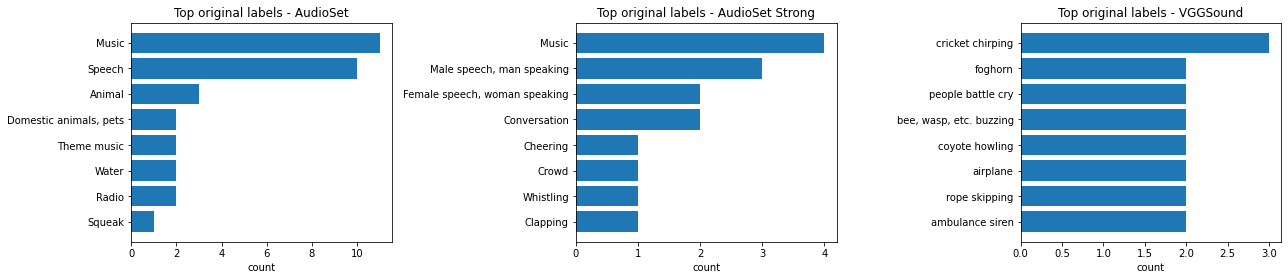

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (title, dataset) in zip(axes, [("AudioSet", audioset), ("AudioSet Strong", strong), ("VGGSound", vgg)]):
    counts = dataset.label_counts("original").most_common(8)
    ax.barh([c[0] for c in counts][::-1], [c[1] for c in counts][::-1])
    ax.set_title(f"Top original labels - {title}")
    ax.set_xlabel("count")
plt.tight_layout()
plt.show()

## 8. One filtering API: original names, ids and SALT labels

`filter_labels(...)` works the same way for every dataset. `label_space` is `original`, `id`, `salt` or `auto`; `match` is `any`, `all` or `none`; `include_descendants=True` expands SALT labels (for example `vehicle`) with their descendants. Comparison ignores case and repeated whitespace.

In [11]:
speech_original = audioset.filter_labels(["Speech"], label_space="original")
speech_by_mid = audioset.filter_labels(["/m/09x0r"], label_space="id")
music_and_speech = audioset.filter_labels(["Music", "Speech"], label_space="original", match="all")
no_speech = audioset.filter_labels(["Speech"], label_space="original", match="none")
vehicle_flat = vgg.filter_labels(["vehicle"], label_space="salt")
vehicle_tree = vgg.filter_labels(["vehicle"], label_space="salt", include_descendants=True)
music_tree = audioset.filter_labels(["music"], label_space="salt", include_descendants=True)

print("AudioSet Speech by original label :", len(speech_original))
print("AudioSet Speech by MID            :", len(speech_by_mid))
print("AudioSet with Music AND Speech    :", len(music_and_speech))
print("AudioSet without Speech           :", len(no_speech))
print("VGGSound 'vehicle' (no descendants):", len(vehicle_flat))
print("VGGSound 'vehicle' + descendants   :", len(vehicle_tree), sorted({r.original_labels[0] for r in vehicle_tree}))
print("AudioSet 'music' + descendants     :", len(music_tree))

AudioSet Speech by original label : 10
AudioSet Speech by MID            : 10
AudioSet with Music AND Speech    : 4
AudioSet without Speech           : 20
VGGSound 'vehicle' (no descendants): 0
VGGSound 'vehicle' + descendants   : 5 ['airplane', 'ambulance siren', 'car engine starting']
AudioSet 'music' + descendants     : 11


In [12]:
# Equivalent functional helpers (they also accept a path instead of a dataset).
functional_vehicle = filter_labels(PATHS["vggsound"], ["vehicle"], salt_resolver=salt, label_space="salt", include_descendants=True)
functional_rest = blacklist_labels(vgg, ["vehicle"], label_space="salt", include_descendants=True)
print("filter_labels   :", len(functional_vehicle))
print("blacklist_labels:", len(functional_rest))
print("sum equals total:", len(functional_vehicle) + len(functional_rest) == len(vgg))

filter_labels   : 5
blacklist_labels: 35
sum equals total: True


## 9. Ranges, grouping and YouTube-id lookup

`select_range` is zero-based and half-open (v1 `select_by_samp_idx(2, 5)` is `select_range(1, 4)`). `find_*` functions return records, one per clip.

In [13]:
small_vgg = vgg.select_range(0, 10)
print("first 10 VGG records:", len(small_vgg), [r.source_id for r in small_vgg[:3]])
print("VGGSound split sizes:", {split: len(group) for split, group in vgg.group_by("split").items()})

found = find_samples_by_youtube_ids(vgg, ["--CC5pH97q4"])
print("one video, two segments:", [(r.source_id, r.original_labels[0]) for r in found])

matched = find_samples_by_samples(vgg.select_range(0, 5), vgg)
print("records sharing a video with the first five:", len(matched))

first 10 VGG records: 10 ['---g-f_I2yQ_1', '--0PQM4-hqg_30', '--56QUhyDQM_185']
VGGSound split sizes: {'test': 2, 'train': 38}
one video, two segments: [('--CC5pH97q4_4', 'foghorn'), ('--CC5pH97q4_33', 'foghorn')]
records sharing a video with the first five: 5


## 10. Merge, deduplication and rebalancing

`merge_datasets(...)` concatenates and removes duplicates (identity = `record_id` fields). `rebalance(...)` undersamples towards the smallest label bucket with a seeded generator; with multi-label clips the final per-label counts are **not** exactly equal (see `docs/rebalancing.md`).

In [14]:
merged = merge_datasets(vgg.select_range(0, 5), vgg.select_range(3, 8))
print("merge 0:5 + 3:8 with dedup:", len(merged), [r.source_id for r in merged][:3], "...")

focus = ["foghorn", "cricket chirping"]
focused = vgg.filter_labels(focus, label_space="original")
balanced = focused.rebalance(focus_labels=focus, label_space="original", random_state=0)
print("VGG focused counts :", dict(focused.label_counts("original")))
print("VGG balanced counts:", dict(balanced.label_counts("original")))

focus = ["Music", "Speech"]
balanced = audioset.rebalance(focus_labels=focus, label_space="original", random_state=0)
buckets = {label: sum(label in r.original_labels for r in audioset) for label in focus}
print("AudioSet buckets", buckets, "-> m =", min(buckets.values()), "-> selected", len(balanced))
print("per-label counts after rebalancing (equal here by chance; with co-occurring labels they are only guaranteed to be >= m):",
      {label: sum(label in r.original_labels for r in balanced) for label in focus})

again = rebalance(audioset, focus_labels=focus, label_space="original", random_state=0)
print("same seed, same selection and order:", [r.source_id for r in again] == [r.source_id for r in balanced])

merge 0:5 + 3:8 with dedup: 8 ['---g-f_I2yQ_1', '--0PQM4-hqg_30', '--56QUhyDQM_185'] ...
VGG focused counts : {'cricket chirping': 3, 'foghorn': 2}
VGG balanced counts: {'cricket chirping': 2, 'foghorn': 2}
AudioSet buckets {'Music': 11, 'Speech': 10} -> m = 10 -> selected 16
per-label counts after rebalancing (equal here by chance; with co-occurring labels they are only guaranteed to be >= m): {'Music': 10, 'Speech': 10}
same seed, same selection and order: True


## 11. Record identity

Every record has a stable content hash, `record_id` (SHA-1 of a canonical JSON of dataset, source id, YouTube id, interval, MIDs and names). SALT labels, split, events, raw fields and path are not part of it, so adding a SALT mapping does not change the identifier.

In [15]:
with_salt = audioset[0]
without_salt = AudioDataset.from_file(PATHS["audioset_eval"], labels_file=PATHS["audioset_labels"])[0]
print("record_id          :", with_salt.record_id)
print("same without SALT  :", without_salt.record_id == with_salt.record_id, "| salt labels:", with_salt.salt_labels, "vs", without_salt.salt_labels)
print("unique in the file :", len({r.record_id for r in audioset}) == len(audioset))

record_id          : 568e1904abd5debf5c752cb6c5cdc315604a950a
same without SALT  : True | salt labels: ('animal', 'dog') vs ()
unique in the file : True


## 12. Normalized JSON/CSV export and lossless reload

Exports are derived artifacts; the original files are never touched. Both formats can be read back and give equal records (including events and raw fields).

In [16]:
subset = vehicle_tree.select_range(0, 5)
json_path = OUTPUT_DIR / "vgg_vehicle_subset.normalized.json"
csv_path = OUTPUT_DIR / "vgg_vehicle_subset.normalized.csv"
subset.to_json(json_path)
subset.to_csv(csv_path)
print("JSON:", json_path.name, json_path.stat().st_size, "bytes | CSV:", csv_path.name, csv_path.stat().st_size, "bytes")
print("detected as:", detect_format(json_path), "/", detect_format(csv_path))
print("lossless JSON round trip:", load_dataset(json_path).records == subset.records)
print("lossless CSV round trip :", load_dataset(csv_path).records == subset.records)
print("CSV header:", csv_path.read_text(encoding="utf-8").splitlines()[0])

strong_csv = OUTPUT_DIR / "strong.normalized.csv"
strong.to_csv(strong_csv)
print("Strong records with events survive the CSV too:", load_dataset(strong_csv).records == strong.records)

JSON: vgg_vehicle_subset.normalized.json 3180 bytes | CSV: vgg_vehicle_subset.normalized.csv 1860 bytes
detected as: Normalized / Normalized
lossless JSON round trip: True
lossless CSV round trip : True
CSV header: dataset,source_id,youtube_id,start_seconds,end_seconds,original_label_ids,original_labels,salt_labels,split,events,raw,source_path,record_id
Strong records with events survive the CSV too: True


## 13. AudioSet Strong: temporal events, tracks and piano roll

Strong rows are grouped by segment; each `AudioRecord` holds `TemporalEvent` objects. The event utilities work on the dataset, not on a separate `_strong` module.

In [17]:
strong_one = strong.select_range(0, 1)
record = strong_one[0]
print("segment:", record.source_id, "| clip interval:", record.start_seconds, record.end_seconds, "| events:", len(record.events))
show_table([{"start": e.start_seconds, "end": e.end_seconds, "label": e.original_label, "salt": e.salt_labels}
            for e in record.events])

segment: s9d-2nhuJCQ_30000 | clip interval: 30.0 40.0 | events: 6
start | end   | label     | salt            
------+-------+-----------+-----------------
0.0   | 10.0  | Music     | ('music',)      
2.627 | 7.237 | Cheering  | ()              
2.627 | 9.239 | Crowd     | ()              
5.634 | 6.649 | Whistling | ('human_voice',)
7.201 | 8.56  | Clapping  | ()              
8.089 | 9.23  | Whistling | ('human_voice',)


number of event tracks: 5
s9d-2nhuJCQ_30000_Music                  bins=20 active=20
s9d-2nhuJCQ_30000_Cheering               bins=20 active=10
s9d-2nhuJCQ_30000_Crowd                  bins=20 active=14
s9d-2nhuJCQ_30000_Whistling              bins=20 active=6


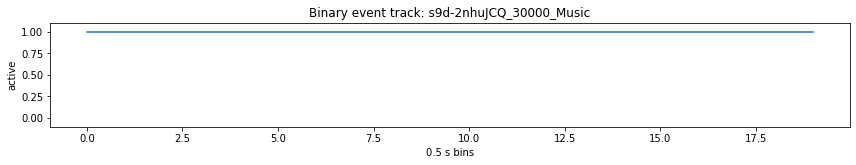

In [18]:
tracks = generate_event_tracks(strong_one, bin_size=0.5, label_space="original")
print("number of event tracks:", len(tracks))
for key, track in tracks[:4]:
    print(f"{key:40s} bins={len(track)} active={int(track.sum())}")

key, track = tracks[0]
fig, ax = plt.subplots(figsize=(12, 2.4))
ax.step(range(len(track)), track, where="post")
ax.set_title(f"Binary event track: {key}")
ax.set_xlabel("0.5 s bins")
ax.set_ylabel("active")
ax.set_ylim(-0.1, 1.1)
plt.tight_layout()
plt.show()

piano-roll figures generated: 1


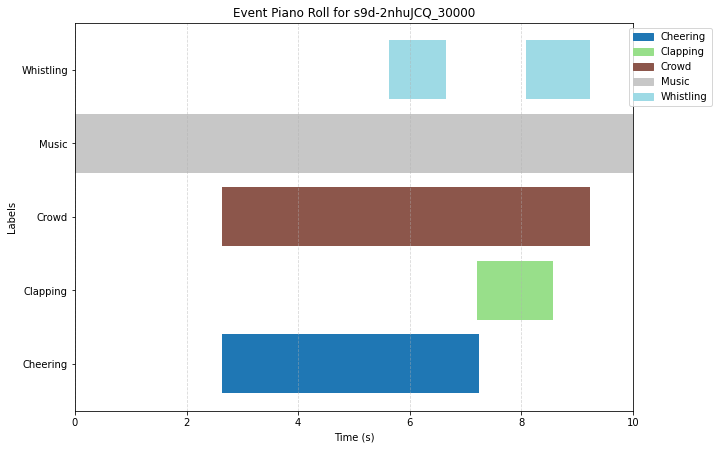

In [19]:
figures = plot_events_pianoroll(strong_one, label_space="original", save_plots=False)
print("piano-roll figures generated:", len(figures))
plt.show()

## 14. Download jobs and the dry-run downloader

`to_download_jobs()` converts records into requests. Real downloading needs the `download` extra and `ffmpeg`; this demo uses `dry_run=True`, so **nothing is downloaded**. Options such as `on_exists="skip"` (resume), `random_pause`, `halt_on_shadow_ban`, cookies and a refresh hook are described in `docs/downloader.md`.

In [20]:
jobs = vgg.select_range(0, 3).to_download_jobs()
for job in jobs:
    print(job.source_id, job.start_seconds, job.end_seconds, job.original_labels)

downloader = YouTubeDatasetDownloader(output_dir=OUTPUT_DIR / "downloads", target_sr=32000, channels="mono",
                                      normalize=True, dry_run=True, on_exists="skip")
report_path = OUTPUT_DIR / "download_report.dry_run.json"
entries = downloader.download_jobs(jobs, report_path=report_path)
show_table([{"source_id": e.source_id, "status": e.status, "success": e.success, "requested": Path(e.requested_output_path).name}
            for e in entries])

---g-f_I2yQ_1 1.0 11.0 ('people marching',)
--0PQM4-hqg_30 30.0 40.0 ('waterfall burbling',)
--56QUhyDQM_185 185.0 195.0 ('playing tennis',)
source_id       | status          | success | requested          
----------------+-----------------+---------+--------------------
---g-f_I2yQ_1   | skipped_dry_run | True    | ---g-f_I2yQ_1.wav  
--0PQM4-hqg_30  | skipped_dry_run | True    | --0PQM4-hqg_30.wav 
--56QUhyDQM_185 | skipped_dry_run | True    | --56QUhyDQM_185.wav


In [21]:
loaded_report = read_download_report(report_path)
print("report entries:", len(loaded_report))
print(json.dumps({k: loaded_report[0][k] for k in ("source_id", "youtube_id", "status", "success", "retry_count")}, indent=2))

invalid = downloader.download_job(DownloadJob(dataset=VGGSOUND, source_id="bad-row", youtube_id="not-valid"))
print("malformed YouTube id ->", invalid.status, "|", invalid.error_category, "|", invalid.error_message)

report entries: 3
{
  "source_id": "---g-f_I2yQ_1",
  "youtube_id": "---g-f_I2yQ",
  "status": "skipped_dry_run",
  "success": true,
  "retry_count": 0
}
malformed YouTube id -> invalid_metadata | InvalidYouTubeId | Malformed YouTube ID: not-valid


## 15. Functional API and object-oriented API

Both styles are available; the object-oriented one is convenient for longer workflows, the functional one for compact scripts.

In [22]:
obj_result = (AudioDataset.from_file(PATHS["vggsound"], salt_resolver=salt)
              .filter_labels(["vehicle"], label_space="salt", include_descendants=True)
              .select_range(0, 3))
fn_result = select_range(filter_labels(PATHS["vggsound"], ["vehicle"], salt_resolver=salt, label_space="salt",
                                       include_descendants=True), 0, 3)
print("object-oriented:", [r.source_id for r in obj_result])
print("functional      :", [r.source_id for r in fn_result])
print("same result     :", obj_result.records == fn_result.records)

object-oriented: ['--8puiAGLhs_30', '--SvivLlKLU_137', '--SvivLlKLU_662']
functional      : ['--8puiAGLhs_30', '--SvivLlKLU_137', '--SvivLlKLU_662']
same result     : True


## 16. Complete mini workflow: a SALT-aware vehicle subset

Parsing, SALT, filtering, statistics, export and download-job generation for the VGGSound excerpt.

records: 5 | unique YouTube ids: 3 | splits: {'train': 5}
original labels: {'car engine starting': 1, 'airplane': 2, 'ambulance siren': 2}
SALT labels    : {'engine': 1, 'aircraft': 2, 'ambulance_siren': 2}
export: vehicle_subset.json | download jobs: 5


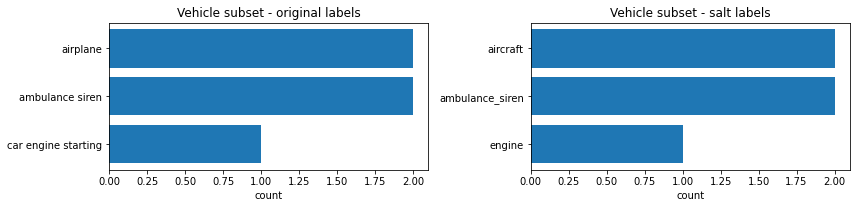

In [23]:
vehicle_subset = load_dataset(PATHS["vggsound"], salt_resolver=salt).filter_labels(
    ["vehicle"], label_space="salt", include_descendants=True)
stats = compute_stats(vehicle_subset)
subset_path = OUTPUT_DIR / "vehicle_subset.json"
vehicle_subset.to_json(subset_path)
print("records:", stats["records"], "| unique YouTube ids:", stats["unique_youtube_ids"], "| splits:", stats["splits"])
print("original labels:", dict(vehicle_subset.label_counts("original")))
print("SALT labels    :", dict(vehicle_subset.label_counts("salt")))
print("export:", subset_path.name, "| download jobs:", len(vehicle_subset.to_download_jobs()))

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, space in zip(axes, ["original", "salt"]):
    counts = vehicle_subset.label_counts(space).most_common(8)
    ax.barh([c[0] for c in counts][::-1], [c[1] for c in counts][::-1])
    ax.set_title(f"Vehicle subset - {space} labels")
    ax.set_xlabel("count")
plt.tight_layout()
plt.show()

## 17. Summary

Demonstrated: automatic format detection; normalized parsing of AudioSet Standard, AudioSet Strong and VGGSound; label maps; the SALT label space with descendant expansion; filtering in the `id`/`original`/`salt` spaces and blacklisting through `match="none"`; ranges, grouping and YouTube-id lookup; merge, deduplication and seeded rebalancing; the stable `record_id`; lossless JSON/CSV export; event tracks and piano rolls; download jobs, the dry-run downloader and its JSON reports.

The excerpts under `tests/data` are never modified; this notebook writes only to a temporary folder.